In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data analysis and visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_GothatarLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,54.360528,%,2025-10-12 06:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-10-12,06:45:00
1,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,51.080333,%,2025-10-12 07:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-10-12,07:45:00
2,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,42.371125,%,2025-10-12 08:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-10-12,08:45:00
3,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,40.663944,%,2025-10-12 09:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-10-12,09:45:00
4,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,37.478667,%,2025-10-12 10:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-10-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,49.635333,%,2025-11-23 23:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-11-23,23:45:00
996,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,49.816833,%,2025-11-24 00:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-11-24,00:45:00
997,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,49.766833,%,2025-11-24 01:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-11-24,01:45:00
998,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,50.080833,%,2025-11-24 02:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2025-11-24,02:45:00


In [3]:
df365['date'].unique()

<ArrowStringArray>
['2025-10-12', '2025-10-13', '2025-10-14', '2025-10-15', '2025-10-16',
 '2025-10-17', '2025-10-18', '2025-10-19', '2025-10-20', '2025-10-21',
 '2025-10-22', '2025-10-23', '2025-10-24', '2025-10-25', '2025-10-26',
 '2025-10-27', '2025-10-28', '2025-10-29', '2025-10-30', '2025-10-31',
 '2025-11-01', '2025-11-02', '2025-11-03', '2025-11-04', '2025-11-05',
 '2025-11-06', '2025-11-07', '2025-11-08', '2025-11-09', '2025-11-10',
 '2025-11-11', '2025-11-12', '2025-11-13', '2025-11-14', '2025-11-15',
 '2025-11-16', '2025-11-17', '2025-11-18', '2025-11-19', '2025-11-20',
 '2025-11-21', '2025-11-22', '2025-11-23', '2025-11-24']
Length: 44, dtype: str

In [4]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df365.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)


In [5]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2025-10-12,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,42.55,18
1,2025-10-13,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,43.80,24
2,2025-10-14,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,45.18,24
3,2025-10-15,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,45.64,24
4,2025-10-16,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,46.60,24
5,2025-10-17,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,48.73,24
6,2025-10-18,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,48.23,24
7,2025-10-19,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,46.14,24
8,2025-10-20,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,44.77,21
9,2025-10-21,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,43.57,24


In [23]:
daily.columns

Index(['date', 'relativehumidity_daily_mean', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

/tmp/ipykernel_32738/2403254589.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


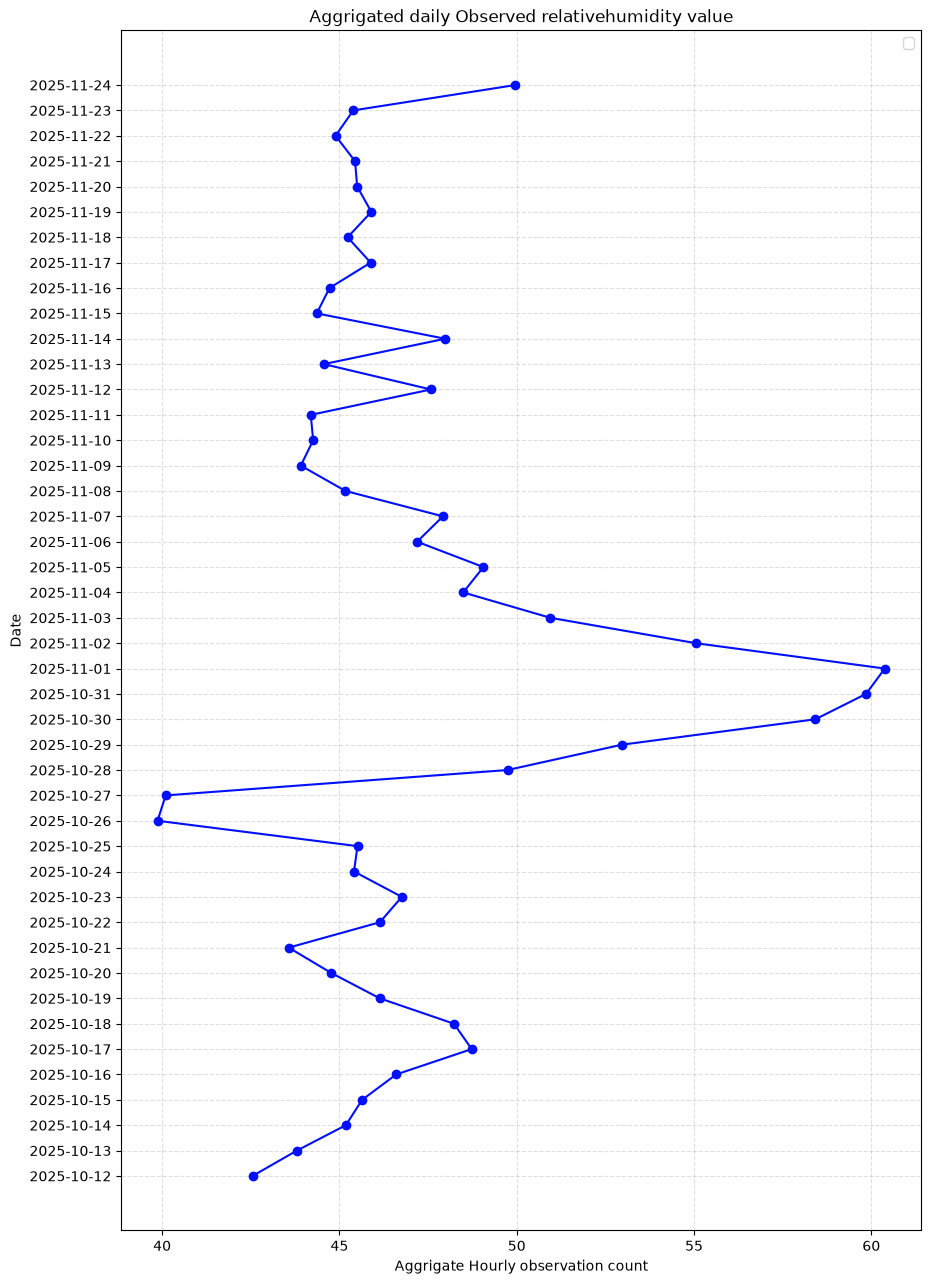

In [8]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and Visualization of last 30 days

In [9]:
df30 = pd.read_csv('cleaned_GothatarLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,59.0,%,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-09-12,06:45:00
1,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-09-12,07:45:00
2,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,50.0,%,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-09-12,08:45:00
3,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,44.0,%,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-09-12,09:45:00
4,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,43.0,%,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
709,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
710,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,55.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
711,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
712,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,57.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [10]:
df30['date'].unique

<bound method Series.unique of 0      2026-09-12
1      2026-09-12
2      2026-09-12
3      2026-09-12
4      2026-09-12
          ...    
709    2026-10-12
710    2026-10-12
711    2026-10-12
712    2026-10-12
713    2026-10-12
Name: date, Length: 714, dtype: str>

In [11]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df30.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [12]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-09-12,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,50.17,18
1,2026-09-13,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,51.88,24
2,2026-09-14,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,53.92,24
3,2026-09-15,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,53.21,24
4,2026-09-16,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,51.00,24
5,2026-09-17,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,50.71,24
6,2026-09-18,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,52.71,24
7,2026-09-19,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,53.00,24
8,2026-09-20,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,51.71,24
9,2026-09-21,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,51.04,24


/tmp/ipykernel_32738/1124759186.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


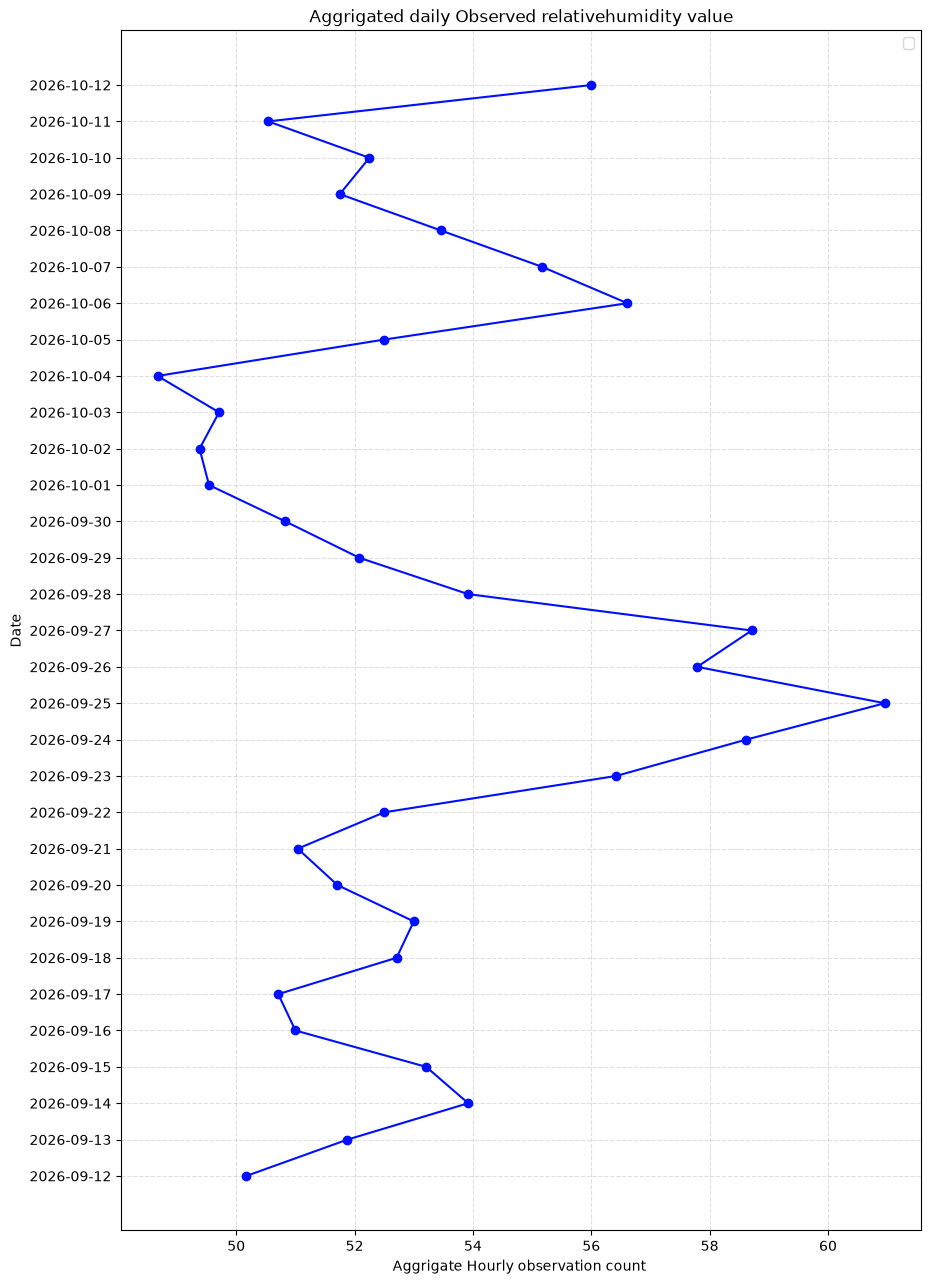

In [13]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 7 days

In [14]:
df7 = pd.read_csv('cleaned_GothatarLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,53.0,%,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,52.0,%,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,51.0,%,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,44.0,%,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
158,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,55.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
159,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,56.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
160,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,57.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [15]:
df7['date'].unique()

<ArrowStringArray>
['2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09',
 '2026-10-10', '2026-10-11', '2026-10-12']
Length: 8, dtype: str

In [16]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df30.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [17]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-09-12,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,50.17,18
1,2026-09-13,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,51.88,24
2,2026-09-14,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,53.92,24
3,2026-09-15,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,53.21,24
4,2026-09-16,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,51.00,24
5,2026-09-17,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,50.71,24
6,2026-09-18,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,52.71,24
7,2026-09-19,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,53.00,24
8,2026-09-20,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,51.71,24
9,2026-09-21,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,51.04,24


/tmp/ipykernel_32738/3434928225.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


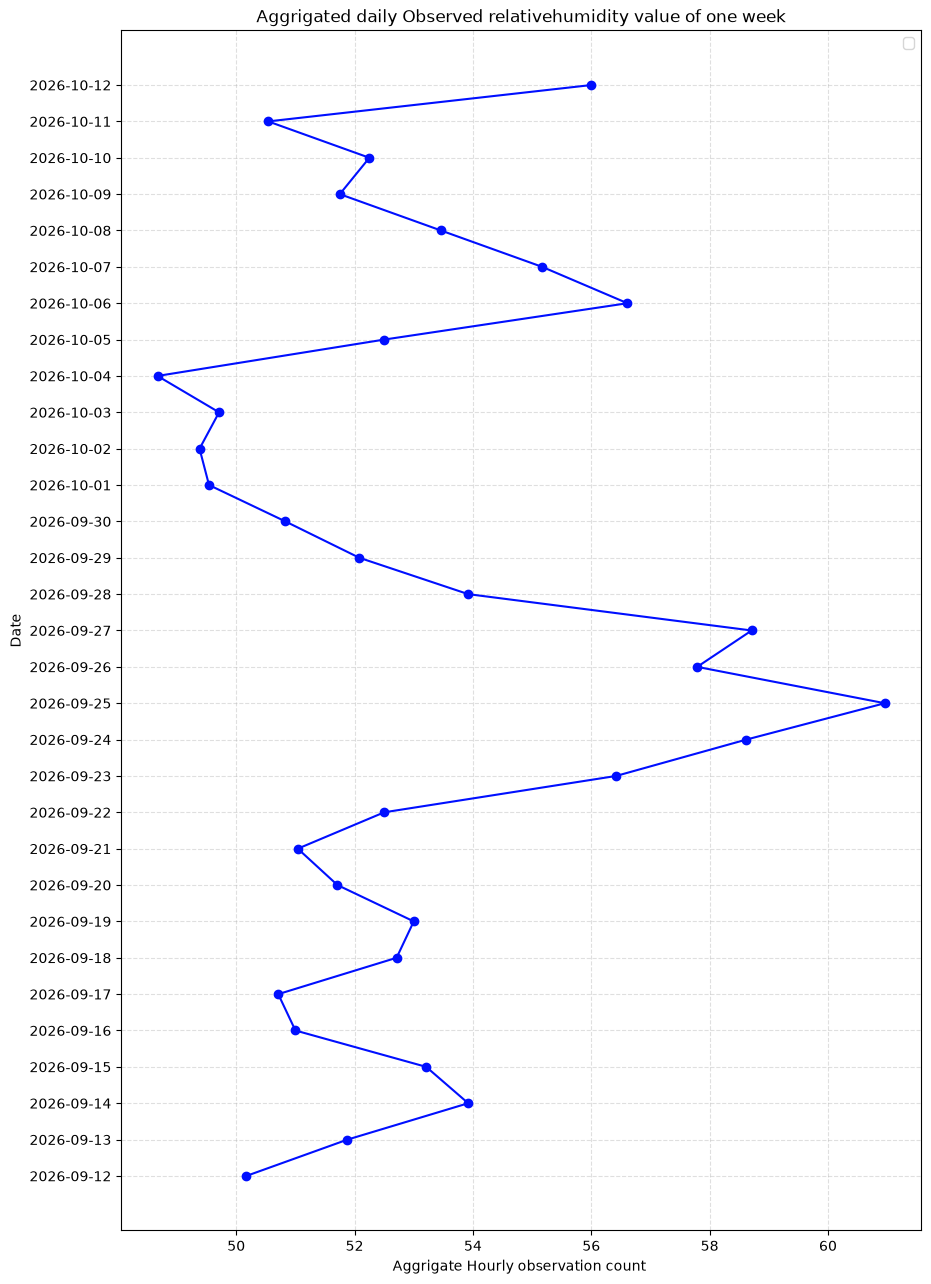

In [18]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [19]:
df24 = pd.read_csv('cleaned_GothatarLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,58.0,%,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,57.0,%,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,52.0,%,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,49.0,%,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,44.0,%,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,39.0,%,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,40.0,%,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,41.0,%,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,42.0,%,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,6071242,Gothatar (SC-12) - GD Labs,relativehumidity,42.0,%,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.710911,85.380372,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


In [20]:
df24['time'].unique()

<ArrowStringArray>
['06:45:00', '07:45:00', '08:45:00', '09:45:00', '10:45:00', '11:45:00',
 '12:45:00', '13:45:00', '14:45:00', '15:45:00', '16:45:00', '17:45:00',
 '18:45:00', '19:45:00', '20:45:00', '21:45:00', '22:45:00', '23:45:00',
 '00:45:00', '01:45:00', '02:45:00', '03:45:00', '04:45:00', '05:45:00']
Length: 24, dtype: str

In [21]:
df24.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

/tmp/ipykernel_32738/1036584907.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


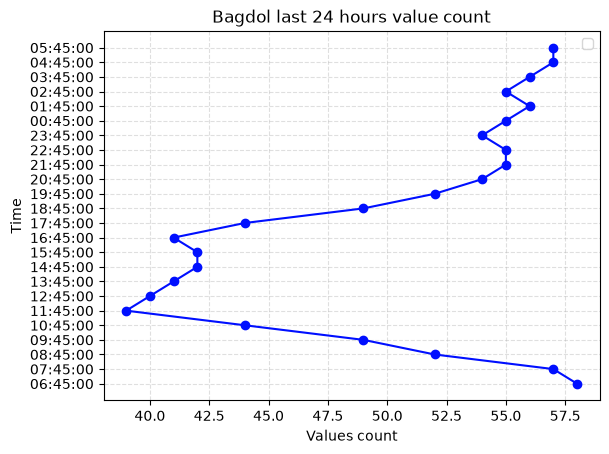

In [22]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Bagdol last 24 hours value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()